intro_to_Language_modeling part1

[link](https://youtu.be/PaCmpygFfXo)

Demonstrate the bigram model of predicting next char using two way
1. explicit way - we find the frequency/count of bigram, normalize it and then calculting the loss
2. using neural network - we train with inputs with random weights and calculate the loss and then use gradient descent optimization to reduce the loss to findally reach desired weights

In [177]:
# download the training data
!curl https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt -o names.txt


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  222k  100  222k    0     0   809k      0 --:--:-- --:--:-- --:--:--  813k


In [178]:
# read the file and create a list of words based on newline
words = open('names.txt','r').read().splitlines()
#min(len(w) for w in words)
#max(len(w) for w in words)
words[:2] # just checking first two items in list

['emma', 'olivia']

**Sample Bigram model**
A bigram model attempts to predict the probability of the correctness of a sequence of words or characters by predicting the occurrence of the one word or character after the other

Training
--------

In [179]:
b = {} # dictionary to store bigram and its occurence(count)
for w in words:
  chs = ['<S>'] + list(w) + ['<E>'] # adding a start and end constant token
  #print(chs, chs[1:])
  for ch1, ch2 in zip(chs,chs[1:]):
    bigram = (ch1, ch2) # tuple closest indivual characters
    b[bigram] = b.get(bigram,0) + 1 #adding k,v to dict. where value is the occurance/count

In [180]:
# sorts the dictionary by the second element(i.e count) in reverse order.
# By default the sort uses the first element in dict(ie key, which is bigram in this case), instead we sort by value(ie occurance/count)
sorted(b.items(), key = lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [181]:
# instead of using dictionary to store bigram and count we could use 2D tensor
# In this 2D tensor, rows are going to be the first char in bigram and columns the second char
# and each entry in this 2D gives the count of occurance of how often the second char follows the first
import torch

In [182]:
# a 2D tensor with initial values as int zero
N = torch.zeros((28,28), dtype=torch.int32)

In [183]:
chars = sorted(list(set(''.join(words)))) # a sorted list of all characters from words
stoi = {s:i for i,s in enumerate(chars)} # a dict of bigram:index
len(stoi) # this should be 26
stoi['<S>'] = 26 # add special start token to dict
stoi['<E>'] = 27 # add special end token to dict

In [184]:
for w in words:
  chs = ['<S>'] + list(w) + ['<E>']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    N[ix1, ix2] += 1 # increment by 1 if character group(bigram) appears repeatedly

In [185]:
itos = {i:s for s,i in stoi.items()} # a dict of index:bigram

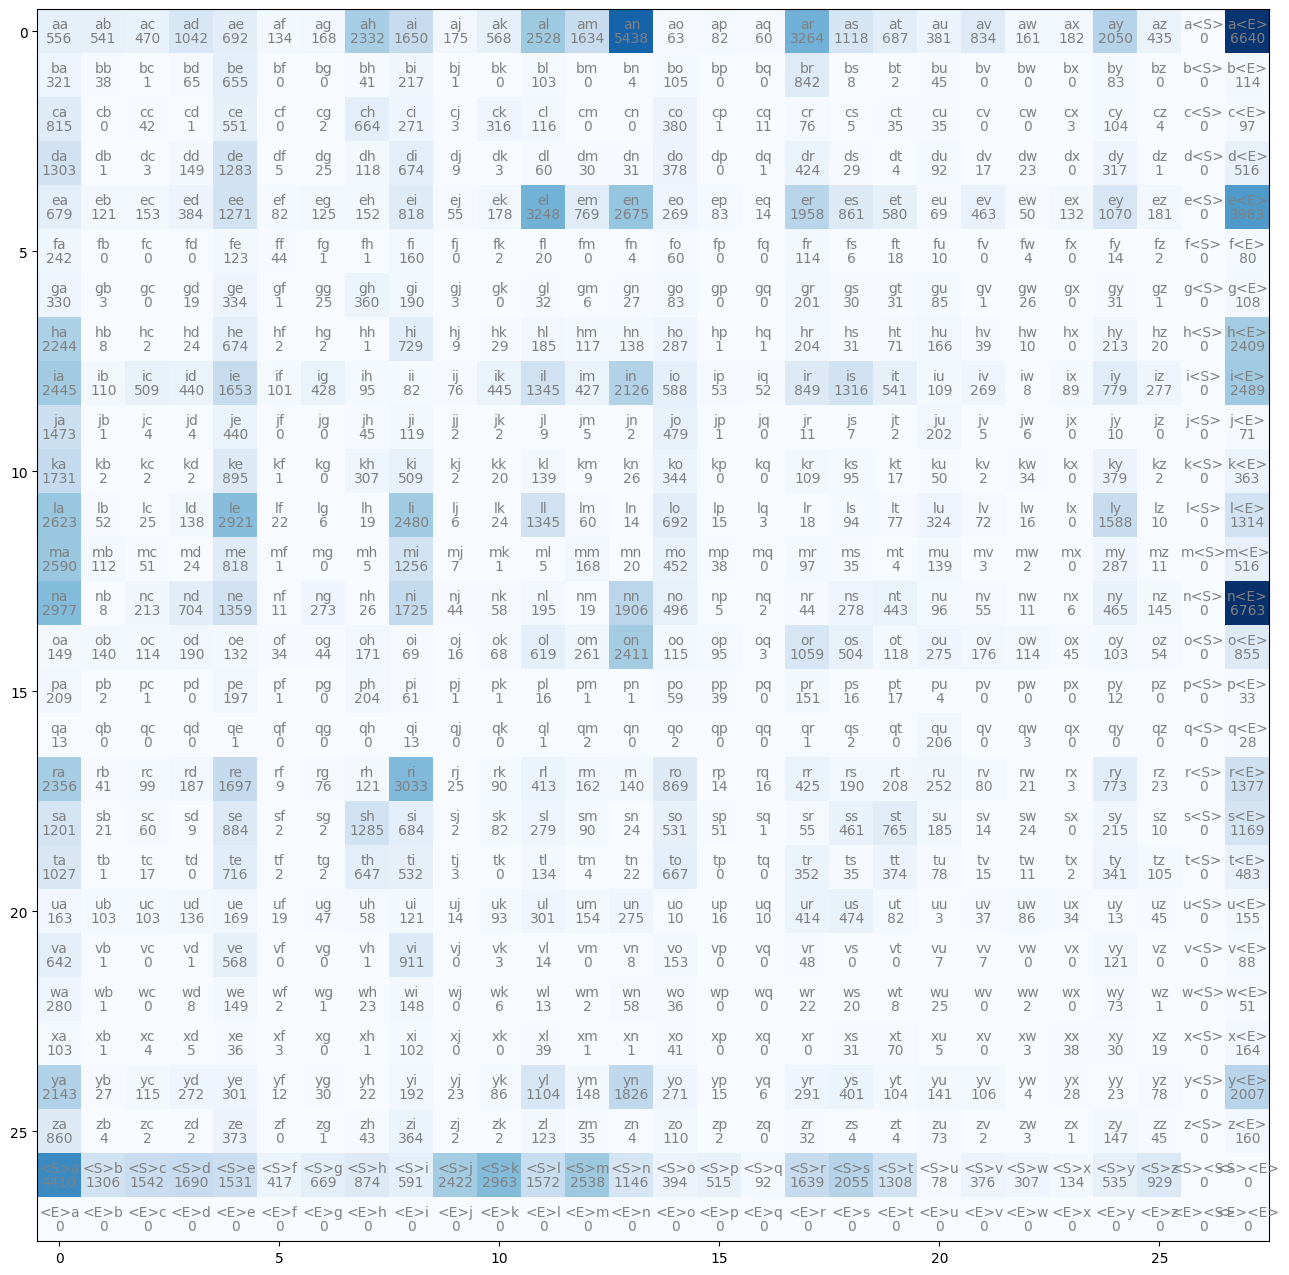

In [186]:
# ploting the 2D tensor
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(28):
    for j in range(28):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
#plt.axis('off');

In [187]:
# revised code, using '.' as the start/end token instead of '<S>' and '<E>'
# this elements the all zero value row for <E> and all zero column as shown in above ploted diagram
N = torch.zeros((27, 27), dtype=torch.int32)

In [188]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [189]:
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    N[ix1, ix2] += 1

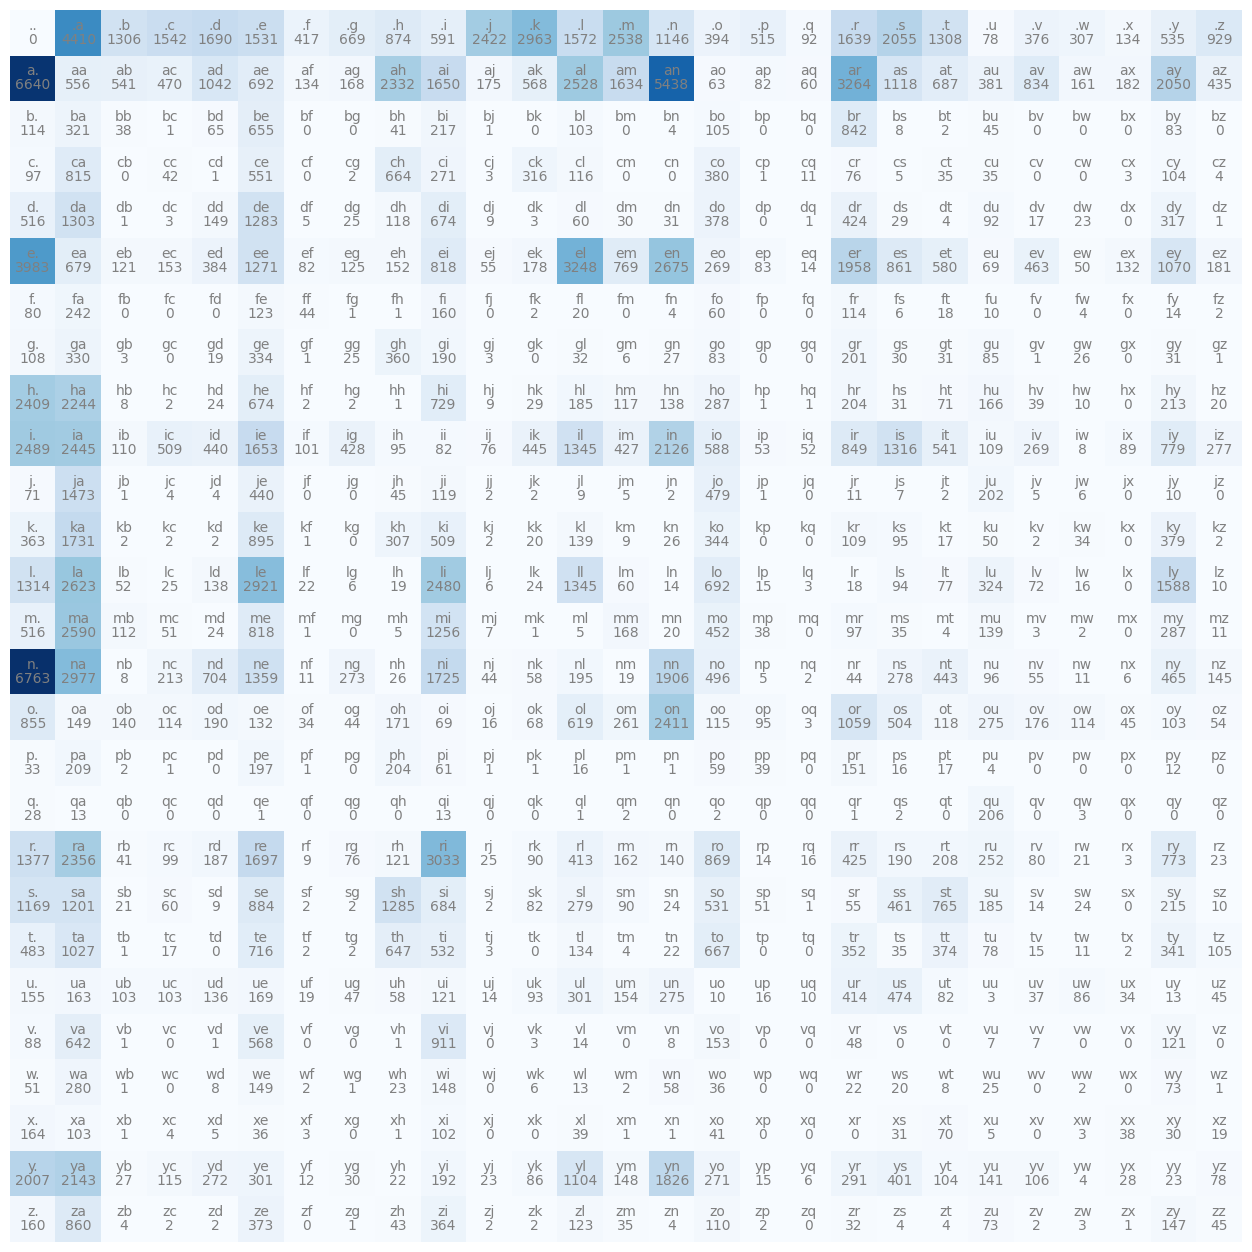

In [190]:
# ploting the 2D tensor
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

Sampling
----------

In [191]:
# # optional: demonstarting the sampling using totch.multinomial With a randomly generated probablity distribution
# g = torch.Generator().manual_seed(2147483647) # generator used to make values deterministic
# p = torch.rand(3, generator=g) # 3 random values generated
# p = p / p.sum() # probablity distribution for the 3 values
# p # this should output tensor([0.6064, 0.3033, 0.0903])

# # do sampling using torch.multinomial
# torch.multinomial(p, num_samples=20, replacement=True, generator=g)

In [192]:
N[0] # first row values of 2d tensor

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [193]:
p = N[0].float() # convert first row values to float
p = p/p.sum() # creating a probablity distribution for items in first row
p # since we have took first row, the probablities we get indicates how likely a single char be the starting char of a word

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

generating samples from the probability distribution of first row

In [194]:
#generating just one sample index out of first rows distributions
g = torch.Generator().manual_seed(2147483647) # generator used to make values deterministic
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
print("index:",ix) # values could be diff each time
print("char:",itos[ix])

index: 10
char: j


In [195]:
# now we try generating a single sample based on our (first row's)distribution
g = torch.Generator().manual_seed(2147483647)

out = []
ix = 0 # corresponds to the '.' character
while True:
  p = N[ix].float() # row zero.
  p = p/p.sum() # probablity distribution
  # get a sample based on probablity distribution of row
  ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
  #print(ix,itos[ix])
  out.append(itos[ix])

  if ix == 0:
    break
print(''.join(out))

junide.


generating couple of samples based on first row

In [196]:
# now we try generating couple of samples based on first rows
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  out = []
  interout = {}
  ix = 0 # corresponds to the '.' character
  while True:
    # p = torch.ones(27)/27.0 # completely untrained where all values will be equally distributed

    p = N[ix].float() # first row values converted to float so as to find probablity distribution
    p = p/p.sum() # probablity distribution of first row

    # get a sample based on probablity distribution of row
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()

    interout[ix] = itos[ix]
    out.append(itos[ix])

    if ix == 0:
      break
  outj = ''.join(out)
  print(outj, f'{interout=}')

junide. interout={10: 'j', 21: 'u', 14: 'n', 9: 'i', 4: 'd', 5: 'e', 0: '.'}
janasah. interout={10: 'j', 1: 'a', 14: 'n', 19: 's', 8: 'h', 0: '.'}
p. interout={16: 'p', 0: '.'}
cony. interout={3: 'c', 15: 'o', 14: 'n', 25: 'y', 0: '.'}
a. interout={1: 'a', 0: '.'}


In [197]:
# now we do some optimization for above code. We move out the tensor float converstion and calculation of probablity distribution from above code
# Instead we introduce a new tensor capital P , which is tensor of probablity distributions

# We create a new tensor and also we do 'model smoothing' by adding a fake count(here we add 1).so that every element in tensor has a fake count(i.e 1) instead of 0
# The reason being that when we calaculate loss func. If we have probablity 0,then log(prod) could result in infinit
P = (N+1).float() # a new tensor that cast values to float

#P.sum() # will sum all the elements
#P.sum(0) # sums each rows(ie adds up columns in each row)
#P.sum(0).shape # shape will be 1D vector [27]
# P.sum(0, keepdim=True) # sums each rows(ie adds up columns in each row)
# P.sum(0, keepdim=True).shape # shape will be 2D vector [1,27]

# P.sum(dim=1, keepdim=True) # sums each columns(ie adds up rows in each column)
# P.sum(1, keepdim=True).shape  # shape will be 2D vector [27,1]

# ensure tensor broadcasting is possible for the opertaion(i.e in this case division between two tenstors).check the broadcasting rule https://docs.pytorch.org/docs/stable/notes/broadcasting.html#general-semantics
# P = P / P.sum(dim=1, keepdim=True) # finding probablity distribution
P /= P.sum(dim=1, keepdim=True) # this improves performace as it uses in place operration rather than creating a new tensor P as above

In [198]:
# updated to use the new P tensor that contains probablity distributions
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  out = []
  interout = {}
  ix = 0 # corresponds to the '.' character
  while True:
    p = P[ix]

    # get a sample based on probablity distribution of row
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()

    interout[ix] = itos[ix]
    out.append(itos[ix])

    if ix == 0:
      break
  outj = ''.join(out)
  print(outj, f'{interout=}')

junide. interout={10: 'j', 21: 'u', 14: 'n', 9: 'i', 4: 'd', 5: 'e', 0: '.'}
janasah. interout={10: 'j', 1: 'a', 14: 'n', 19: 's', 8: 'h', 0: '.'}
p. interout={16: 'p', 0: '.'}
cony. interout={3: 'c', 15: 'o', 14: 'n', 25: 'y', 0: '.'}
a. interout={1: 'a', 0: '.'}


Finding qality of the model / finding loss
---------

In [199]:
# just printing few bigram and its probablity
for w in words[:3]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    prob = P[ix1, ix2]
    print(f'{ch1}, {ch2}: {prob:.4f}')


., e: 0.0478
e, m: 0.0377
m, m: 0.0253
m, a: 0.3885
a, .: 0.1958
., o: 0.0123
o, l: 0.0779
l, i: 0.1774
i, v: 0.0152
v, i: 0.3508
i, a: 0.1380
a, .: 0.1958
., a: 0.1376
a, v: 0.0246
v, a: 0.2473
a, .: 0.1958


In [200]:
# calculating the loss
# ===GOAL====
# maximize likelihood of the data w.r.t. model parameters (statistical modeling)
# equivalent to maximizing the log likelihood (because log is monotonic)
# equivalent to minimizing the negative log likelihood
# equivalent to minimizing the average negative log likelihood

log_likelihood = 0.0
n = 0

for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    prob = P[ix1, ix2] # fetching probablity of bigram from tensor
    # finding log of probablity https://www.wolframalpha.com/input?i=log%28x%29+from+0+to+1
    logprob = torch.log(prob) #This log(prob) should be between 0 and negative infinite. if prob= 1 then log(prob) = 0 and as prob decrease it goes to negative values
    log_likelihood += logprob # log likelihood is the sum of logprob
    n += 1
    #print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(f'{log_likelihood=}')
nll = -log_likelihood # for convience, inverting log likelihood to make it negative likelihood
print(f'{nll=}')
# the low the following number(i.e close to 0), better the model is
print(f'{nll/n}') # for convience, we normalize negative log likelihood(ie average the negative log likelihood)


log_likelihood=tensor(-559951.5625)
nll=tensor(559951.5625)
2.4543561935424805


Tuning to reduce loss - using neuralnet
---------
Here we create a new neural network with the same dataset and finally do back pass to reduce loss

First we create a training set - Here for simplicity we taking only the first word ('emma')

In [201]:
#create the training set of bigrams (x,y) for the neural net
xs, ys = [], [] # 'xs' are list of input chars and 'ys' are the expected next chars for those xs input

for w in words[:1]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    print(ch1, ch2)
    xs.append(ix1) #xs list stores the index of first char in bigram
    ys.append(ix2) #xs list stores the index of secon char in bigram

xs = torch.tensor(xs) #converting list to a tensor . xs is the input
ys = torch.tensor(ys) #converting list to a tensor . ys is the labels/expected next chars
print(xs, ys)

. e
e m
m m
m a
a .
tensor([ 0,  5, 13, 13,  1]) tensor([ 5, 13, 13,  1,  0])


In [202]:
# convert the input(xs) to vectors understandable by neural net
import torch.nn.functional as F
xenc = F.one_hot(xs, num_classes=27).float() # here we use one hot encoding
xenc
# xenc.shape # this should be 5 X 27

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

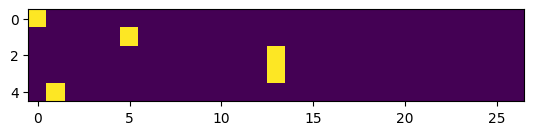

In [203]:
plt.imshow(xenc)

In [204]:
# Generating random weights(for a single neuron) using randn (standard normal distribution)

# In the context of building a neural network, this W tensor represents weights of a single neuron.
# Here we use size 27, because the input to this neuron will be a vector of size 27 (representing a one-hot encoded character) and the weights need to have a compatible size for doing  matrix multiplication.
W = torch.randn((27, 1))
#print(W)

# matrix multiplication of inputs(xenc) and weights(W). basically finding the summazation(ofcouse without bias)
xenc @ W #matrix multiplication of shape 5X27 @ 27X1 = 5X1

tensor([[-0.7662],
        [ 0.5146],
        [ 0.1850],
        [ 0.1850],
        [ 1.3984]])

Instead of just one nueron we create 27 neurons and here is why we need more neurons

1.Representing Multiple Possibilities:

A single neuron, with its single output, can only capture one linear combination of the input features.
For example, if the input is the character 'a', the next character could be 'b', 'c', 'd', etc., each with a different probability. A single output can't effectively represent the probabilities of all these possibilities simultaneously

2.Learning Complex Relationships

3.Predicting Probabilities for Each Possible Next Character:

In [205]:
# random weights for 27 neurons
W = torch.randn((27, 27))
#print(W)

# matrix multiplication of inputs and weight
xenc @ W #matrix multiplication of shape 5X27 @ 27X27 = 5X27

# value we get is the firing rate of each 27 neurons for the 5inputs(xenc)

tensor([[ 0.3208,  0.7471,  0.0253, -0.0330,  1.2184, -0.3358,  0.1175, -0.5905,
         -0.2401,  0.1446,  1.1919,  1.3657, -0.7813,  1.0907,  0.6860, -0.5577,
          0.7196,  0.7953, -0.7643,  0.6133, -0.5607,  3.0831,  1.0809, -0.0591,
          0.8587, -0.2416,  0.5248],
        [ 0.7519, -0.7295,  0.7045,  1.0586, -1.1615,  1.6311, -0.3095, -0.4205,
          0.5056, -0.6721, -0.9779,  0.9213, -0.3912,  0.6480, -1.4748, -0.4944,
          0.0292, -1.8002,  0.2175,  0.3761, -0.0958,  0.4744,  1.0211, -1.5520,
          0.6771,  0.8638,  0.8618],
        [-1.5045,  0.9739,  0.6631,  0.9647, -0.0082, -0.7693,  0.5450,  0.7385,
         -0.0168,  0.8376, -0.7929,  0.0127,  0.5032,  1.1672, -0.8402,  1.2985,
         -0.4979, -1.9301,  0.1178, -0.6297, -0.4633, -0.9070, -0.8501, -0.5898,
          0.0140, -0.8180,  0.1144],
        [-1.5045,  0.9739,  0.6631,  0.9647, -0.0082, -0.7693,  0.5450,  0.7385,
         -0.0168,  0.8376, -0.7929,  0.0127,  0.5032,  1.1672, -0.8402,  1.2985

In [206]:
(xenc @ W)[3, 13] # prints the firing rate of 13th nueron for the 3rd input

tensor(1.1672)

####Tansforming neuralnet outputs into probablities

For tasks like predicting the next character, we need neurons outputs to represent probabilities, which must be between 0 and 1 and sum up to 1 across all possible next characters.

The outputs(firing rates) from 27 neurons should have been either a probablity(number between 0 and 1) or a count (similar to earlier tensor N where we had counts/occurance of characters pairs)

Here we use exponentiation [exp(x)](https://www.wolframalpha.com/input?i=exp%28x%29) to convert to probablity. What exp does is for negative numbers it will be less than 1 and for postive it will be greater than 1

In [207]:
logits = xenc @ W # log-counts. matrix multiplication of inputs and weight

# the below two lines constitute softmax
counts = logits.exp() # exponentiation to transforms any real number into a positive number
probs = counts / counts.sum(1, keepdims=True) # probability distribution
probs

tensor([[0.0215, 0.0329, 0.0160, 0.0151, 0.0528, 0.0111, 0.0175, 0.0086, 0.0123,
         0.0180, 0.0514, 0.0611, 0.0071, 0.0464, 0.0310, 0.0089, 0.0320, 0.0346,
         0.0073, 0.0288, 0.0089, 0.3405, 0.0460, 0.0147, 0.0368, 0.0123, 0.0264],
        [0.0545, 0.0124, 0.0520, 0.0741, 0.0080, 0.1313, 0.0189, 0.0169, 0.0426,
         0.0131, 0.0097, 0.0646, 0.0174, 0.0491, 0.0059, 0.0157, 0.0265, 0.0042,
         0.0319, 0.0374, 0.0234, 0.0413, 0.0714, 0.0054, 0.0506, 0.0610, 0.0608],
        [0.0066, 0.0792, 0.0581, 0.0785, 0.0297, 0.0139, 0.0516, 0.0626, 0.0294,
         0.0691, 0.0135, 0.0303, 0.0495, 0.0961, 0.0129, 0.1096, 0.0182, 0.0043,
         0.0337, 0.0159, 0.0188, 0.0121, 0.0128, 0.0166, 0.0303, 0.0132, 0.0335],
        [0.0066, 0.0792, 0.0581, 0.0785, 0.0297, 0.0139, 0.0516, 0.0626, 0.0294,
         0.0691, 0.0135, 0.0303, 0.0495, 0.0961, 0.0129, 0.1096, 0.0182, 0.0043,
         0.0337, 0.0159, 0.0188, 0.0121, 0.0128, 0.0166, 0.0303, 0.0132, 0.0335],
        [0.0569, 0.0354,

In [208]:
probs[0].sum() # sum of problity of first row

tensor(1.0000)

####Summary of above neural network

In [209]:
# input data set
xs

tensor([ 0,  5, 13, 13,  1])

In [210]:
# labels, showing target/correct next char
ys

tensor([ 5, 13, 13,  1,  0])

In [211]:
# randomly initialize 27 neurons' weights. each neuron receives 27 inputs
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g)

In [212]:
# forward pass to get probabilities

xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
logits = xenc @ W # predict log-counts

counts = logits.exp() # counts similar to N tensor
probs = counts / counts.sum(1, keepdims=True) # probablity distributions
# btw: the last 2 lines here are together called a 'softmax'

In [213]:
probs.shape

torch.Size([5, 27])

In [214]:
# calculate loss
nlls = torch.zeros(5)
for i in range(5): # using 5 here as we have 5 bigrams for emma
  # i-th bigram:
  x = xs[i].item() # input character index
  y = ys[i].item() # label character index
  print('--------')
  print(f'bigram example {i+1}: {itos[x]}{itos[y]} (indexes {x},{y})')
  print('input to the neural net:', x)
  print('output probabilities from the neural net:', probs[i])
  print('label (actual next character):', y)
  p = probs[i, y]
  print('probability assigned by the net to the the correct character:', p.item())
  logp = torch.log(p)
  print('log likelihood:', logp.item())
  nll = -logp
  print('negative log likelihood:', nll.item())
  nlls[i] = nll

print('=========')
print('average negative log likelihood, i.e. loss =', nlls.mean().item())

--------
bigram example 1: .e (indexes 0,5)
input to the neural net: 0
output probabilities from the neural net: tensor([0.0607, 0.0100, 0.0123, 0.0042, 0.0168, 0.0123, 0.0027, 0.0232, 0.0137,
        0.0313, 0.0079, 0.0278, 0.0091, 0.0082, 0.0500, 0.2378, 0.0603, 0.0025,
        0.0249, 0.0055, 0.0339, 0.0109, 0.0029, 0.0198, 0.0118, 0.1537, 0.1459])
label (actual next character): 5
probability assigned by the net to the the correct character: 0.01228625513613224
log likelihood: -4.399273872375488
negative log likelihood: 4.399273872375488
--------
bigram example 2: em (indexes 5,13)
input to the neural net: 5
output probabilities from the neural net: tensor([0.0290, 0.0796, 0.0248, 0.0521, 0.1989, 0.0289, 0.0094, 0.0335, 0.0097,
        0.0301, 0.0702, 0.0228, 0.0115, 0.0181, 0.0108, 0.0315, 0.0291, 0.0045,
        0.0916, 0.0215, 0.0486, 0.0300, 0.0501, 0.0027, 0.0118, 0.0022, 0.0472])
label (actual next character): 13
probability assigned by the net to the the correct character: 0.

####Additional optimizing and gradient based optimization to reduce loss

In [215]:
xs

tensor([ 0,  5, 13, 13,  1])

In [216]:
ys

tensor([ 5, 13, 13,  1,  0])

In [217]:
# randomly initialize 27 neurons' weights. each neuron receives 27 inputs
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

In [218]:
# forward pass
xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
logits = xenc @ W # predict log-counts
counts = logits.exp() # counts similar to N tensor
probs = counts / counts.sum(1, keepdims=True) # probablity distributions

# find loss
#probs[torch.arange(5), ys] # the probablity of getting ys based on the 5 inputs
#probs[torch.arange(5), ys].log() # the log(prob) should be a value between 0 and negative infinite. if prob= 1 then log(prob) = 0 and as prob decrease it goes to negative values
loss = -probs[torch.arange(5), ys].log().mean() # optimized loss calculation. gets probablities based on input and output, calculates log of it and then the mean in one go
loss.item()

3.7693049907684326

In [219]:
# backward pass
W.grad = None # set to zero gradient
loss.backward()
#W[0,0].data

In [220]:
print(f'weight={W[0,0].data},grad={W.grad[0,0]}')

weight=1.5673619508743286,grad=0.012134450487792492


In [221]:
# update weights # this is gradient descenting
W.data += -0.1 * W.grad # gradient based optimization. weights increased by a small value of its gradent

####Final optimization with entire dataset

In [222]:
# create the entire training set
xs, ys = [], []
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ', num)

# initialize the 'network'
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

number of examples:  228146


In the following code, in addition to the 'average negative log likelihood' we are also using a regularization term when calculate loss .ie "0.01*(W**2).mean()"

Adding the regularization term to the negative log likelihood is a common technique to help prevent overfitting. Overfitting occurs when the model becomes too complex and learns the training data too well, including its noise, which can lead to poor performance on new, unseen data. By adding this regularization term, the loss function encourages the model to keep the weights of the neural network small. Smaller weights generally lead to a simpler model, which is less likely to overfit. The value 0.01 is a tunable parameter that is often found through experimentation

In [223]:
# gradient descent
for k in range(100):

  # forward pass
  xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
  logits = xenc @ W # predict log-counts
  counts = logits.exp() #logits is exponentiated to counts
  probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
  #loss = -probs[torch.arange(num), ys].log().mean()
  # loss calculation with regularization. the additional '0.01*(W**2).mean()' is for regularization loss. where 0.01 is called the regularization strength
  loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W**2).mean()
  print(loss.item())

  # backward pass
  W.grad = None # set to zero the gradient
  loss.backward()

  # update
  W.data += -50 * W.grad #

3.7686190605163574
3.3788065910339355
3.16109037399292
3.0271859169006348
2.9344842433929443
2.867231607437134
2.8166542053222656
2.777146339416504
2.7452542781829834
2.7188303470611572
2.696505546569824
2.6773719787597656
2.6608052253723145
2.6463515758514404
2.633664846420288
2.622471570968628
2.6125476360321045
2.6037068367004395
2.595794916152954
2.5886809825897217
2.5822560787200928
2.5764293670654297
2.5711236000061035
2.5662729740142822
2.5618228912353516
2.5577263832092285
2.5539441108703613
2.550442695617676
2.5471925735473633
2.5441696643829346
2.5413522720336914
2.538722038269043
2.536262035369873
2.5339581966400146
2.531797409057617
2.529768228530884
2.527859926223755
2.5260636806488037
2.5243701934814453
2.522773265838623
2.52126407623291
2.519836902618408
2.5184857845306396
2.5172054767608643
2.515990734100342
2.5148372650146484
2.5137407779693604
2.512697696685791
2.511704921722412
2.5107581615448
2.509854555130005
2.5089924335479736
2.5081682205200195
2.507380485534668


####Finally do some sampling on the neuralnet model

In [225]:
# finally, sample from the 'neural net' model to generate new sequences of characters using the neural network
g = torch.Generator().manual_seed(2147483647)

for i in range(5): # runs 5 times, generating 5 different sample sequences

  out = []
  interout = {}
  ix = 0 # sets the initial character index to 0, which corresponds to the '.' character. This means each generated sequence will begin with '.'
  while True: # oop continues generating characters until an end token is produced

    # creates a one-hot encoded tensor for the current character index ix. This tensor is the input to our neural network.
    xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
    logits = xenc @ W # predict log-counts
    counts = logits.exp() # counts, equivalent to N
    p = counts / counts.sum(1, keepdims=True) # probabilities for next character

    #a sample next character index based on the calculated probability distribution
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    interout[ix] = itos[ix]

    if ix == 0:
      break
  outj = ''.join(out)
  print(outj, f'{interout=}')

junide. interout={10: 'j', 21: 'u', 14: 'n', 9: 'i', 4: 'd', 5: 'e', 0: '.'}
janasah. interout={10: 'j', 1: 'a', 14: 'n', 19: 's', 8: 'h', 0: '.'}
p. interout={16: 'p', 0: '.'}
cfay. interout={3: 'c', 6: 'f', 1: 'a', 25: 'y', 0: '.'}
a. interout={1: 'a', 0: '.'}
